# 01 — Dataset analizi və təmizlənməsi

**Dataset:** Kaggle SQL Injection Dataset (sajid576), `Modified_SQL_Dataset.csv`.
**Məqsəd:** datasetin quruluşunu, sinif balansını, dublikatları və ziddiyyətli label-ləri yoxlamaq,
sonra təmiz versiyanı `data/processed/clean.csv` kimi saxlamaq.

Qaydalar: seed = 42, qrafiklər `figures/` (300 dpi PNG), cədvəllər `results/` (CSV).

## 1. Mühit və yollar
Kitabxanaları yükləyir, random seed-i 42-yə bərkidir və layihə qovluqlarını təyin edirik.
Notebook `notebooks/` daxilindən işə salındığı üçün layihə kökü bir səviyyə yuxarıdır.

In [1]:
import random
import re
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAW_DIR = ROOT / "data" / "raw"
PROC_DIR = ROOT / "data" / "processed"
FIG_DIR = ROOT / "figures"
RES_DIR = ROOT / "results"
for d in (PROC_DIR, FIG_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Sinif rəngləri: 0 = təmiz (mavi), 1 = zərərli (narıncı)
COLORS = {0: "#2a78d6", 1: "#eb6834"}
NAMES = {0: "Təmiz (0)", 1: "Zərərli (1)"}
plt.rcParams.update({
    "figure.dpi": 110,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e4e0",
    "grid.linewidth": 0.6,
    "axes.axisbelow": True,
    "axes.edgecolor": "#8a8984",
    "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e",
    "ytick.color": "#52514e",
})

def save_fig(fig, name):
    fig.savefig(FIG_DIR / name, dpi=300, bbox_inches="tight")

## 2. Datasetin yüklənməsi
`data/raw/` qovluğundakı CSV faylını oxuyuruq. Sorğuları olduğu kimi saxlamaq üçün
`keep_default_na=False` istifadə edirik (yoxsa `"NULL"`, `"NA"` kimi sorğu mətnləri NaN-a çevrilər);
boş dəyərləri sonra özümüz yoxlayırıq.

In [2]:
csv_files = sorted(RAW_DIR.glob("*.csv"))
print("Tapılan fayllar:", [f.name for f in csv_files])
assert len(csv_files) == 1, "data/raw/ qovluğunda tam olaraq bir CSV gözlənilir"

df_raw = pd.read_csv(csv_files[0], keep_default_na=False, dtype=str, encoding="utf-8")
print("Sütunlar:", df_raw.columns.tolist())
df_raw.head(10)

Tapılan fayllar: ['Modified_SQL_Dataset.csv']
Sütunlar: ['Query', 'Label']


,Query,Label
0,""" or pg_sleep ( __TIME__ ) --",1
1,create user name identified by pass123 tempora...,1
2,AND 1 = utl_inaddr.get_host_address ( ...,1
3,select * from users where id = '1' or @ @1 ...,1
4,"select * from users where id = 1 or 1#"" ( ...",1
5,select name from syscolumns where id = ...,1
6,select * from users where id = 1 +$+ or 1 =...,1
7,"1; ( load_file ( char ( 47,101,116,99,47...",1
8,select * from users where id = '1' or ||/1 ...,1
9,select * from users where id = '1' or \.<\ ...,1


## 3. Ümumi ölçü və label dəyərləri
Label sütununda yalnız `0` və `1` olduğunu yoxlayırıq; gözlənilməz dəyər varsa, ayrıca göstəririk.

In [3]:
print("Ümumi ölçü (sətir, sütun):", df_raw.shape)
print("\nLabel sütununun dəyərləri:")
print(df_raw["Label"].value_counts(dropna=False))

Ümumi ölçü (sətir, sütun): (30919, 2)

Label sütununun dəyərləri:
Label
0    19537
1    11382
Name: count, dtype: int64


## 4. Sinif balansı
Hər sinifdə neçə sorğu olduğunu və faizini hesablayıb bar chart çəkirik.

       count  percent
Label                
0      19537    63.19
1      11382    36.81


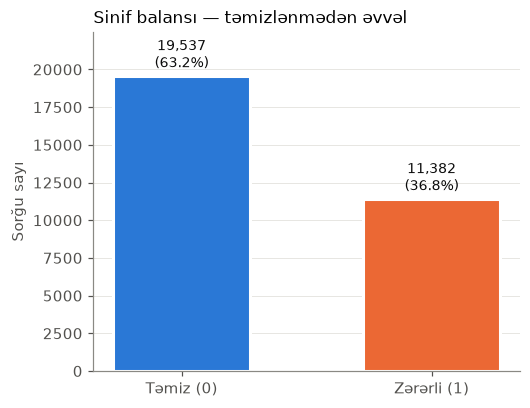

In [4]:
def class_balance(frame):
    counts = frame["Label"].value_counts().sort_index()
    return pd.DataFrame({"count": counts, "percent": (counts / counts.sum() * 100).round(2)})

df = df_raw.copy()
df["Label"] = pd.to_numeric(df["Label"], errors="coerce")
balance_before = class_balance(df.dropna(subset=["Label"]).astype({"Label": int}))
print(balance_before)

def plot_balance(bal, title, fname):
    fig, ax = plt.subplots(figsize=(5, 4))
    labels = list(bal.index)
    bars = ax.bar([NAMES[l] for l in labels], bal["count"], color=[COLORS[l] for l in labels],
                  width=0.55, edgecolor="white", linewidth=2)
    for b, (c, p) in zip(bars, zip(bal["count"], bal["percent"])):
        ax.annotate(f"{c:,}\n({p:.1f}%)", (b.get_x() + b.get_width() / 2, b.get_height()),
                    ha="center", va="bottom", fontsize=9, color="#0b0b0b", xytext=(0, 3),
                    textcoords="offset points")
    ax.set_ylabel("Sorğu sayı")
    ax.set_title(title, loc="left", fontsize=11)
    ax.margins(y=0.15)
    ax.grid(axis="x", visible=False)
    save_fig(fig, fname)
    plt.show()

plot_balance(balance_before, "Sinif balansı — təmizlənmədən əvvəl", "01_class_balance_raw.png")

## 5. Boş dəyərlər
NaN, boş sətir və yalnız boşluqdan ibarət sorğuları sayırıq. Label-i rəqəm olmayan sətirlər də buraya daxildir.

In [5]:
query_empty = df["Query"].str.strip().eq("")
label_nan = df["Label"].isna()
missing = pd.Series({
    "Query NaN": int(df["Query"].isna().sum()),
    "Query boş / yalnız boşluq": int(query_empty.sum()),
    "Label NaN / rəqəm deyil": int(label_nan.sum()),
})
print(missing)
if label_nan.any():
    display(df_raw[label_nan].head(10))

Query NaN                    0
Query boş / yalnız boşluq    1
Label NaN / rəqəm deyil      0
dtype: int64


## 6. Dublikatlar və ziddiyyətli label-lər
Üç səviyyədə yoxlayırıq:
1. **Tam dublikat sətirlər** — eyni sorğu, eyni label.
2. **Təkrarlanan sorğular** — label-dən asılı olmayaraq eyni sorğu mətni.
3. **Ziddiyyətli label-lər** — eyni sorğu həm `0`, həm `1` kimi işarələnib.

Əlavə olaraq, sorğuları normallaşdırıb (kiçik hərf, boşluqlar birləşdirilmiş) "demək olar ki, eyni" sorğuları da sayırıq —
bu, train/test sızmasının (leakage) daha gizli formasıdır.

In [6]:
valid = df[~query_empty & ~label_nan].copy()
valid["Label"] = valid["Label"].astype(int)

exact_dup_rows = int(valid.duplicated(subset=["Query", "Label"]).sum())
dup_query_rows = int(valid.duplicated(subset=["Query"]).sum())
dup_query_groups = int((valid["Query"].value_counts() > 1).sum())

labels_per_query = valid.groupby("Query")["Label"].nunique()
conflict_queries = labels_per_query[labels_per_query > 1].index
conflict_rows = valid[valid["Query"].isin(conflict_queries)]

norm = valid["Query"].str.lower().str.replace(r"\s+", " ", regex=True).str.strip()
norm_dup_rows = int(norm.duplicated().sum())
norm_conflicts = int((valid.groupby(norm)["Label"].nunique() > 1).sum())

dup_summary = pd.Series({
    "Tam dublikat sətirlər (Query+Label)": exact_dup_rows,
    "Təkrarlanan sorğu sətirləri (yalnız Query)": dup_query_rows,
    "Birdən çox dəfə görünən unikal sorğular": dup_query_groups,
    "Fərqli label ilə təkrarlanan unikal sorğular": len(conflict_queries),
    "Ziddiyyətli sorğulara aid sətirlər": len(conflict_rows),
    "Normallaşdırılmış dublikat sətirlər": norm_dup_rows,
    "Normallaşdırılmış ziddiyyətli sorğular": norm_conflicts,
})
print(dup_summary.to_string())
dup_summary.rename("value").to_frame().to_csv(RES_DIR / "01_duplicate_summary.csv", index_label="metric")

print("\nDublikatların sinif üzrə bölgüsü (tam dublikat sətirlər):")
print(valid[valid.duplicated(subset=["Query", "Label"])]["Label"].value_counts().sort_index())

print("\nƏn çox təkrarlanan 10 sorğu:")
display(valid["Query"].value_counts().head(10).rename("təkrar sayı").to_frame())

if len(conflict_queries):
    print("\nZiddiyyətli label nümunələri:")
    display(conflict_rows.sort_values("Query").head(20))

Tam dublikat sətirlər (Query+Label)              12
Təkrarlanan sorğu sətirləri (yalnız Query)       14
Birdən çox dəfə görünən unikal sorğular           8
Fərqli label ilə təkrarlanan unikal sorğular      2
Ziddiyyətli sorğulara aid sətirlər               10
Normallaşdırılmış dublikat sətirlər             102
Normallaşdırılmış ziddiyyətli sorğular            2

Dublikatların sinif üzrə bölgüsü (tam dublikat sətirlər):
Label
0    8
1    4
Name: count, dtype: int64

Ən çox təkrarlanan 10 sorğu:


,təkrar sayı
Query,
#NAME?,8
1,2
1.94E+15,2
1.86E+15,2
7.75E+15,2
28%,2
29%,2
26%,2
""" or pg_sleep ( __TIME__ ) --",1



Ziddiyyətli label nümunələri:


,Query,Label
656,#NAME?,1
866,#NAME?,1
13318,#NAME?,0
13532,#NAME?,0
15635,#NAME?,0
17913,#NAME?,0
18233,#NAME?,0
18875,#NAME?,0
4244,1,1
17499,1,0


## 7. Sorğu uzunluğunun paylanması
Hər sinif üçün simvol sayı ilə uzunluğu hesablayırıq. Paylanma sağa çox əyri olduğundan,
histogram həm xətti, həm də logarifmik x oxunda ayrı-ayrı çəkilir.

,count,mean,std,min,25%,50%,75%,max
Təmiz (0),19537.0,39.9,51.7,1.0,11.0,35.0,56.0,5370.0
Zərərli (1),11381.0,118.6,96.8,1.0,51.0,85.0,150.0,456.0


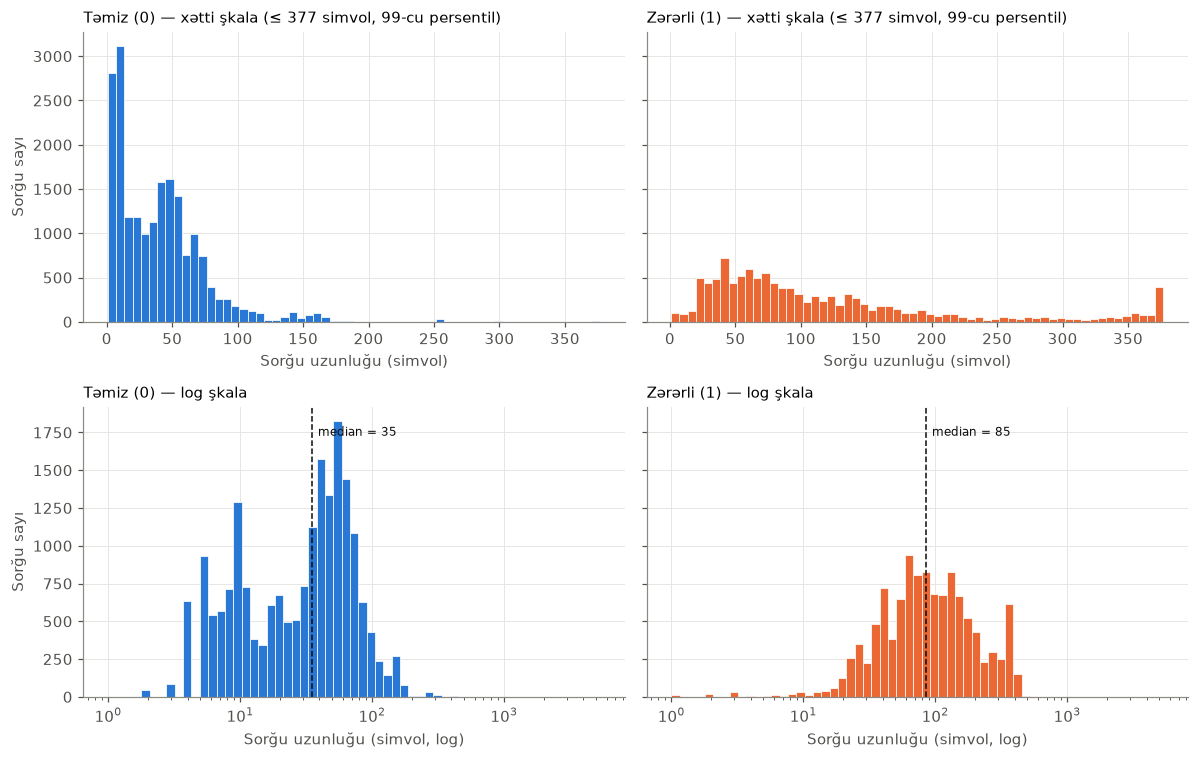

In [7]:
valid["length"] = valid["Query"].str.len()
length_stats = valid.groupby("Label")["length"].describe().round(1)
length_stats.index = [NAMES[i] for i in length_stats.index]
display(length_stats)
length_stats.to_csv(RES_DIR / "01_length_stats_raw.csv")

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharey="row")
clip = int(valid["length"].quantile(0.99))
for col, label in enumerate((0, 1)):
    lens = valid.loc[valid["Label"] == label, "length"]
    ax = axes[0, col]
    ax.hist(lens.clip(upper=clip), bins=60, color=COLORS[label], edgecolor="white", linewidth=0.5)
    ax.set_title(f"{NAMES[label]} — xətti şkala (≤ {clip} simvol, 99-cu persentil)", loc="left", fontsize=10)
    ax.set_xlabel("Sorğu uzunluğu (simvol)")
    ax = axes[1, col]
    bins = np.logspace(0, np.log10(valid["length"].max() + 1), 60)
    ax.hist(lens, bins=bins, color=COLORS[label], edgecolor="white", linewidth=0.5)
    ax.set_xscale("log")
    ax.set_title(f"{NAMES[label]} — log şkala", loc="left", fontsize=10)
    ax.set_xlabel("Sorğu uzunluğu (simvol, log)")
    ax.axvline(lens.median(), color="#0b0b0b", linewidth=1, linestyle="--")
    ax.annotate(f"median = {lens.median():.0f}", (lens.median(), ax.get_ylim()[1] * 0.9),
                xytext=(4, 0), textcoords="offset points", fontsize=8, color="#0b0b0b")
for ax in axes[:, 0]:
    ax.set_ylabel("Sorğu sayı")
fig.tight_layout()
save_fig(fig, "01_query_length_hist.png")
plt.show()

## 8. Zərərli sorğularda ən çox rast gəlinən SQL açar sözləri və simvollar
Hər token üçün **neçə sorğuda ən azı bir dəfə göründüyünü** sayırıq (document frequency) — bu,
bir sorğuda 50 dəfə təkrarlanan simvolun nəticəni təhrif etməsinin qarşısını alır.
Açar sözlər söz sərhədi ilə (`\b`), registrdən asılı olmayaraq axtarılır. Müqayisə üçün
həmin tokenin təmiz sorğulardakı payı da göstərilir — məsələn, `SELECT` təmiz sorğularda da çox ola bilər
və bu, qara siyahı filtrinin niyə yanlış pozitiv verdiyini izah edir.

In [8]:
SQL_KEYWORDS = [
    "SELECT", "UNION", "ALL", "FROM", "WHERE", "AND", "OR", "NOT", "NULL", "INSERT", "INTO", "VALUES",
    "UPDATE", "SET", "DELETE", "DROP", "TABLE", "CREATE", "ALTER", "EXEC", "EXECUTE", "DECLARE",
    "CAST", "CONVERT", "CHAR", "CHR", "CONCAT", "SUBSTRING", "ASCII", "SLEEP", "BENCHMARK",
    "WAITFOR", "DELAY", "PG_SLEEP", "IF", "CASE", "WHEN", "THEN", "ELSE", "END", "LIKE", "ORDER",
    "BY", "GROUP", "HAVING", "LIMIT", "OFFSET", "INFORMATION_SCHEMA", "TABLE_NAME", "COLUMN_NAME",
    "SYSOBJECTS", "XP_CMDSHELL", "LOAD_FILE", "OUTFILE", "DUAL", "VERSION", "USER", "DATABASE",
    "COUNT", "DISTINCT", "JOIN", "AS", "IN", "IS", "EXISTS", "BETWEEN", "TRUE", "FALSE", "RLIKE",
    "REGEXP", "UTL_INADDR", "DBMS_PIPE", "ROWNUM", "MD5", "SHA1", "HEX", "UNHEX", "ORD", "MID",
]
SQL_SYMBOLS = [
    "'", '"', "--", "#", "/*", "*/", ";", "=", "(", ")", ",", "*", "||", "&&", "@@", "@", "%",
    "+", "<", ">", "<>", "!=", "`", "\\", "0x", "%27", "%20", "%23", "||'", "' or '", "1=1",
]

malicious = valid.loc[valid["Label"] == 1, "Query"]
benign = valid.loc[valid["Label"] == 0, "Query"]

def doc_freq(series, token, is_word):
    if is_word:
        pattern = re.compile(rf"(?<![A-Za-z0-9_]){re.escape(token)}(?![A-Za-z0-9_])", re.IGNORECASE)
        return int(series.str.contains(pattern).sum())
    return int(series.str.lower().str.contains(token.lower(), regex=False).sum())

def token_table(tokens, is_word):
    rows = []
    for t in tokens:
        m, b = doc_freq(malicious, t, is_word), doc_freq(benign, t, is_word)
        rows.append({"token": t, "malicious_count": m, "malicious_pct": round(m / len(malicious) * 100, 2),
                     "benign_count": b, "benign_pct": round(b / len(benign) * 100, 2)})
    return pd.DataFrame(rows).sort_values("malicious_count", ascending=False).head(20).reset_index(drop=True)

top_keywords = token_table(SQL_KEYWORDS, is_word=True)
top_symbols = token_table(SQL_SYMBOLS, is_word=False)
top_keywords.to_csv(RES_DIR / "01_top20_keywords_malicious.csv", index=False)
top_symbols.to_csv(RES_DIR / "01_top20_symbols_malicious.csv", index=False)
print("Ən çox rast gəlinən 20 açar söz (zərərli sorğular):")
display(top_keywords)
print("Ən çox rast gəlinən 20 simvol (zərərli sorğular):")
display(top_symbols)

Ən çox rast gəlinən 20 açar söz (zərərli sorğular):


,token,malicious_count,malicious_pct,benign_count,benign_pct
0,SELECT,7123,62.59,10922,55.90
1,AND,4836,42.49,1273,6.52
2,WHERE,4030,35.41,4385,22.44
3,FROM,3892,34.20,10297,52.71
4,OR,3416,30.01,364,1.86
5,AS,2318,20.37,977,5.00
6,UNION,2219,19.50,563,2.88
7,ALL,1849,16.25,242,1.24
8,END,1651,14.51,21,0.11
9,ELSE,1629,14.31,18,0.09


Ən çox rast gəlinən 20 simvol (zərərli sorğular):


,token,malicious_count,malicious_pct,benign_count,benign_pct
0,),9371,82.34,4497,23.02
1,=,9216,80.98,2792,14.29
2,(,7523,66.10,4604,23.57
3,",",6409,56.31,3268,16.73
4,',5310,46.66,3614,18.50
5,--,3970,34.88,2,0.01
6,"""",3317,29.15,294,1.50
7,*,3039,26.70,5655,28.95
8,#,2019,17.74,8,0.04
9,||,1787,15.70,1,0.01


Hər token üçün iki sinifdəki payı yan-yana göstəririk (sorğuların %-i). Eyni ox, eyni şkala.

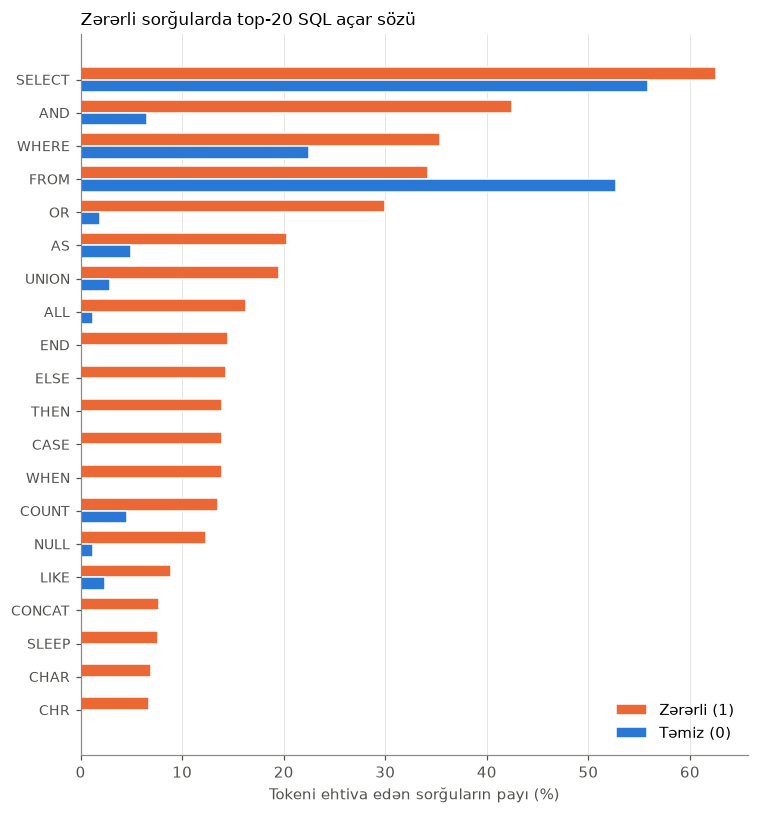

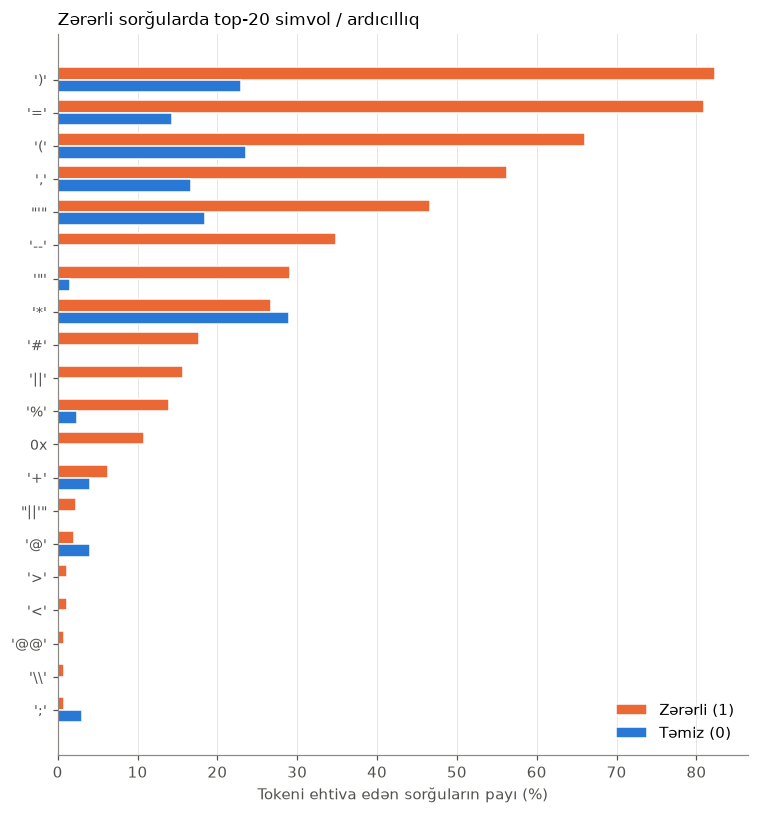

In [9]:
def plot_tokens(table, title, fname):
    t = table.iloc[::-1]
    y = np.arange(len(t))
    h = 0.38
    fig, ax = plt.subplots(figsize=(7, 7.5))
    ax.barh(y + h / 2, t["malicious_pct"], height=h, color=COLORS[1], label=NAMES[1], edgecolor="white", linewidth=1)
    ax.barh(y - h / 2, t["benign_pct"], height=h, color=COLORS[0], label=NAMES[0], edgecolor="white", linewidth=1)
    ax.set_yticks(y, [repr(s) if not s.isalnum() and "_" not in s else s for s in t["token"]], fontsize=9)
    ax.set_xlabel("Tokeni ehtiva edən sorğuların payı (%)")
    ax.set_title(title, loc="left", fontsize=11)
    ax.grid(axis="y", visible=False)
    ax.legend(frameon=False, loc="lower right")
    fig.tight_layout()
    save_fig(fig, fname)
    plt.show()

plot_tokens(top_keywords, "Zərərli sorğularda top-20 SQL açar sözü", "01_top20_keywords.png")
plot_tokens(top_symbols, "Zərərli sorğularda top-20 simvol / ardıcıllıq", "01_top20_symbols.png")

## 9. Təsadüfi nümunələr
Hər sinifdən 5 təsadüfi sorğu (seed = 42). Uzun sorğular 200 simvola qədər qısaldılır.

In [10]:
pd.set_option("display.max_colwidth", 200)
for label in (0, 1):
    print(f"===== {NAMES[label]} =====")
    sample = valid[valid["Label"] == label].sample(5, random_state=SEED)
    for i, q in enumerate(sample["Query"], 1):
        print(f"{i}. {q[:200]!r}")
    print()

===== Təmiz (0) =====
1. 'completorio'
2. 'SELECT COUNT ( DISTINCT appropriate )  FROM completely'
3. 'entendimiento'
4. 'madrigal puigb'
5. 'SELECT number FROM may'

===== Zərərli (1) =====
1. '1 rlike   (  select   (  case when   (  7689  =  7689  )   then 1 else 0x28 end   )    )   -- jduw'
2. "-9829'   )    )     )   or 1 group by concat  (  0x7171706a71,  (  select   (  case when   (  4232  =  4232  )   then 1 else 0 end   )    )   ,0x717a767a71,floor  (  rand  (  0  )  *2   )    )    havi"
3. "1' or exp  (  ~  (  select * from   (  select concat  (  0x7171706a71,  (  select   (  elt  (  6270  =  6270,1   )    )     )  ,0x717a767a71,0x78   )    )   x   )    )    and 'ibdj'  =  'ibdj"
4. '1 and 7533  =  7533# absp'
5. '1"   )    )    as nejd where 2885  =  2885'



## 10. Təmizləmə və saxlama
Təmizləmə qaydaları:
1. Boş / NaN sorğuları və rəqəm olmayan label-ləri silirik.
2. **Ziddiyyətli label-li sorğuları tamamilə silirik** — hansı label-in doğru olduğunu bilmədiyimiz üçün
   birini saxlamaq modelə səs-küy verərdi.
3. Qalan tam dublikatlardan yalnız birinci nüsxəni saxlayırıq.

Sorğu mətnləri dəyişdirilmir (boşluq, registr) — obfuskasiya testləri üçün orijinal forma vacibdir.
Normallaşdırılmış dublikatlar burada silinmir, amma train/test bölgüsündə nəzərə alınmalıdır.

Saxlanıldı: C:\Users\Mehman\OneDrive\Desktop\AI_article\data\processed\clean.csv

Təmizlənmədən sonra sinif balansı:
       count  percent
Label                
0      19527    63.19
1      11375    36.81


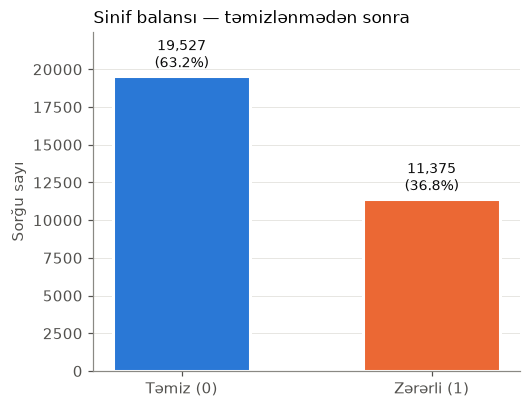

In [11]:
clean = valid[~valid["Query"].isin(conflict_queries)]
clean = clean.drop_duplicates(subset=["Query"], keep="first")[["Query", "Label"]].reset_index(drop=True)

assert clean["Query"].is_unique
assert clean["Label"].isin([0, 1]).all()
clean.to_csv(PROC_DIR / "clean.csv", index=False, encoding="utf-8")
print(f"Saxlanıldı: {PROC_DIR / 'clean.csv'}")

balance_after = class_balance(clean)
print("\nTəmizlənmədən sonra sinif balansı:")
print(balance_after)
plot_balance(balance_after, "Sinif balansı — təmizlənmədən sonra", "01_class_balance_clean.png")

## 11. Xülasə: əvvəl və sonra
Məqalə üçün əsas rəqəmlər `results/01_cleaning_summary.csv` faylına yazılır.

In [12]:
def row(frame):
    vc = frame["Label"].value_counts()
    n = len(frame)
    return {"total": n, "benign_0": int(vc.get(0, 0)), "malicious_1": int(vc.get(1, 0)),
            "benign_pct": round(vc.get(0, 0) / n * 100, 2), "malicious_pct": round(vc.get(1, 0) / n * 100, 2)}

summary = pd.DataFrame([
    {"stage": "raw", **row(df.dropna(subset=["Label"]))},
    {"stage": "clean", **row(clean)},
]).set_index("stage")
summary.loc["raw", "total"] = len(df_raw)  # xam sətir sayı (yanlış label-li sətirlər daxil)
summary["removed_vs_raw"] = len(df_raw) - summary["total"]
summary.to_csv(RES_DIR / "01_cleaning_summary.csv")
display(summary)

,total,benign_0,malicious_1,benign_pct,malicious_pct,removed_vs_raw
stage,,,,,,
raw,30919,19537,11382,63.19,36.81,0
clean,30902,19527,11375,63.19,36.81,17
